#### 0. 환경 설정

In [1]:
import re
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import pymysql
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.inspection import permutation_importance
warnings.filterwarnings('ignore')

pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_columns', 500)

_KO_FONTS = ['NanumGothic', 'NanumBarunGothic', 'Malgun Gothic', 'AppleGothic']
_available = {f.name for f in fm.fontManager.ttflist}
_ko_font = next((f for f in _KO_FONTS if f in _available), None)
if _ko_font:
    plt.rcParams['font.family'] = _ko_font
plt.rcParams['axes.unicode_minus'] = False

PACER_DIR  = './csv_2020'
DATA_DIR   = './data_v3'          # 20260624 노트북에서 생성된 pv_L.pkl(claims 병합 완료) 재사용
NPE_CSV    = './NPE 기업목록(20260611).csv'

DB_HOST, DB_USER, DB_PW = '192.168.1.116', 'root', 'doslvkdlqm!'

RANDOM_STATE = 42
CV_FOLDS = 5

FEATURE_COLS = [
    'MCD', 'SCD',
    'TD_A', 'TD_B', 'TD_C', 'TD_D', 'TD_E', 'TD_F', 'TD_G', 'TD_H',
    'ABS', 'CTS', 'CTC', 'PTS',
    'PK', 'SK', 'PPS',
    'CD', 'IC', 'IE', 'FIE', 'ET',
    'TCP',
    'LI1', 'LI3', 'LI5', 'LI7'
]

print(f'환경 설정 완료  |  PACER_DIR: {PACER_DIR}  |  DATA_DIR: {DATA_DIR}')

환경 설정 완료  |  PACER_DIR: ./csv_2020  |  DATA_DIR: ./data_v3


---
#### 1. 회사명 정규화 함수 

In [2]:
_STATE_PAT  = re.compile(r'\bA\s+(?:CORPORATION\s+)?OF\s+\w{2,4}\.?\b', re.IGNORECASE)
_AKA_PAT    = re.compile(r'[,\s]*(?:A/K/A|D/B/A|F/K/A|T/A|AKA|DBA|FKA|ALSO\s+KNOWN\s+AS|DOING\s+BUSINESS\s+AS|FORMERLY\s+KNOWN\s+AS|TRADING\s+AS)\b.*$', re.IGNORECASE)
_SUFFIX_PAT = re.compile(r'\b(INCORPORATED|CORPORATION|COMPANY|LIMITED|ENTERPRISES|INC|CORP|LLC|LTD|CO|PLC|LP|LLP|GMBH|AG|SA|SL|SRL|BV|NV|AB|AS|KK|THE|AND)\b', re.IGNORECASE)

def normalize_company(name):
    if pd.isna(name): return None
    s = str(name).upper().strip()
    s = _STATE_PAT.sub(' ', s); s = re.sub(r'\.', '', s); s = _AKA_PAT.sub('', s)
    s = re.sub(r'[^\w\s]', ' ', s); s = _SUFFIX_PAT.sub(' ', s); s = re.sub(r'\s+', ' ', s).strip()
    return s if s else None

print('normalize_company 정의 완료')

normalize_company 정의 완료


---
#### 2. PACER 로딩 (원고-특허 매핑용)

In [3]:
cases   = pd.read_csv(f'{PACER_DIR}/cases.csv',   low_memory=False)
patents = pd.read_csv(f'{PACER_DIR}/patents.csv',  low_memory=False)
names   = pd.read_csv(f'{PACER_DIR}/names.csv',    low_memory=False)

for _df in (cases, patents, names):
    _df['case_row_id'] = pd.to_numeric(_df['case_row_id'], errors='coerce')

inf_cases = cases[cases['case_type_1'] == 1.0].copy()

lit_patents = patents[
    (patents['case_row_id'].isin(inf_cases['case_row_id'])) &
    (patents['patent_doc_type'].str.strip() == 'Patent')
].copy()
lit_patents['patent'] = lit_patents['patent'].astype(str).str.strip()

plaintiffs = (
    names[names['party_type'].str.strip().str.lower() == 'plaintiff']
    [['case_row_id', 'name']]
    .drop_duplicates('case_row_id')
    .rename(columns={'name': 'plaintiff'})
)

print(f'침해소송 케이스: {len(inf_cases):,}건  |  소송특허 매핑대상: {len(lit_patents):,}행  |  원고: {plaintiffs["plaintiff"].nunique():,}개')

침해소송 케이스: 60,916건  |  소송특허 매핑대상: 138,260행  |  원고: 40,214개


---
## 3. pv_L 로드 + 원고 단위 확장 피처(`df_new_feat`) 재구성
`./data_v3/pv_L.pkl` (PACER 2020 + claims 병합 완료본) 재사용 — 대용량 PatentsView 파일 재처리 없음.

In [4]:
pv_L = pd.read_pickle(f'{DATA_DIR}/pv_L.pkl')
print(f'pv_L 로드 완료: {len(pv_L):,}건')

plt_pat = (
    plaintiffs.merge(
        lit_patents[['case_row_id', 'patent']].dropna(),
        on='case_row_id', how='inner'
    )
    .drop_duplicates(['plaintiff', 'patent'])
)
plt_pat['patent_id'] = pd.to_numeric(plt_pat['patent'], errors='coerce')
plt_pat['plt_norm']  = plt_pat['plaintiff'].apply(normalize_company)
plt_pat = plt_pat.dropna(subset=['patent_id', 'plt_norm'])
plt_pat['patent_id'] = plt_pat['patent_id'].astype(int)
print(f'원고-특허 매핑: {len(plt_pat):,}행 (원고 {plt_pat["plt_norm"].nunique():,}개)')

feat_avail = [c for c in FEATURE_COLS if c in pv_L.columns and c not in ('LI1', 'LI3', 'LI5', 'LI7')]

plt_feat = plt_pat[['plt_norm', 'patent_id']].merge(pv_L[['patent_id'] + feat_avail], on='patent_id', how='inner')
agg_mean = plt_feat.groupby('plt_norm')[feat_avail].mean().rename(columns={c: f'{c}_mean' for c in feat_avail}).reset_index()
agg_max  = plt_feat.groupby('plt_norm')[feat_avail].max().rename(columns={c: f'{c}_max' for c in feat_avail}).reset_index()
agg_pat_cnt = plt_feat.groupby('plt_norm')['patent_id'].nunique().rename('소송특허수').reset_index()
df_new_feat = agg_mean.merge(agg_max, on='plt_norm').merge(agg_pat_cnt, on='plt_norm')
new_feat_cols = [c for c in df_new_feat.columns if c != 'plt_norm']
print(f'확장 피처 집계 완료: {len(df_new_feat):,}개 기업 / {len(new_feat_cols)}개 피처')

pv_L 로드 완료: 42,652건
원고-특허 매핑: 56,849행 (원고 15,607개)
확장 피처 집계 완료: 15,607개 기업 / 41개 피처


---
#### 4. baseline 4피처 + NPE 라벨 (정확매칭 전용)

In [5]:
conn_ai = pymysql.connect(host=DB_HOST, user=DB_USER, password=DB_PW, database='AI_Evaluation', charset='utf8mb4')
df_liti = pd.read_sql(
    """
    SELECT RGTR_NM, RAW_RGTR_NM,
           PLAINTIFF_COUNT  AS 원고수,
           DEFENDANT_COUNT  AS 피고수,
           REGISTER_COUNT   AS 특허수,
           TRANSFER_COUNT   AS 권리자이전수
    FROM us_transfer_register_litigation
    WHERE RGTR_NM IS NOT NULL
    """,
    conn_ai
)
conn_ai.close()

df_liti['rgtr_norm'] = df_liti['RGTR_NM'].apply(normalize_company)
print(f'us_transfer_register_litigation: {len(df_liti):,}건')

us_transfer_register_litigation: 341,367건


In [6]:
npe_df = pd.read_csv(NPE_CSV, encoding='utf-8-sig')
npe_names_raw  = set(npe_df['company_name'].dropna()) | set(npe_df['subcompany_name'].dropna())
npe_names_norm = {normalize_company(n) for n in npe_names_raw if normalize_company(n)}
print(f'NPE 마스터 목록(정규화): {len(npe_names_norm):,}개')

def is_npe_strict(name):
    """정확매칭만 — 부분문자열 매칭(오탐 다수 확인됨, 20260624 참고) 제거"""
    n = normalize_company(name)
    if not n:
        return 0
    return 1 if n in npe_names_norm else 0

df_liti['is_npe'] = df_liti['RGTR_NM'].apply(is_npe_strict)

n_npe = df_liti['is_npe'].sum()
print(f'NPE 레이블(정확매칭): {n_npe:,}행 / 전체 {len(df_liti):,}행 ({n_npe/len(df_liti):.2%})')
print(f'고유 RGTR_NM: {df_liti["RGTR_NM"].nunique():,}개  |  고유 rgtr_norm: {df_liti["rgtr_norm"].nunique():,}개')

npe_rows = df_liti[df_liti['is_npe'] == 1]
print(f'NPE=1 행: {len(npe_rows):,}건  |  고유 RGTR_NM: {npe_rows["RGTR_NM"].nunique():,}개  |  고유 rgtr_norm: {npe_rows["rgtr_norm"].nunique():,}개')
print('(20260624 부분문자열 포함 버전 비교: 5,239행 / 고유기업 4,452개 — 그중 정확매칭만 1,426행/1,302개)')

NPE 마스터 목록(정규화): 2,341개
NPE 레이블(정확매칭): 1,426행 / 전체 341,367행 (0.42%)
고유 RGTR_NM: 341,367개  |  고유 rgtr_norm: 304,313개
NPE=1 행: 1,426건  |  고유 RGTR_NM: 1,426개  |  고유 rgtr_norm: 1,302개
(20260624 부분문자열 포함 버전 비교: 5,239행 / 고유기업 4,452개 — 그중 정확매칭만 1,426행/1,302개)


---
#### 5. 확장 피처 매칭 + 1:1 균형 데이터셋 재구성 (정확매칭 기준)


In [7]:
df_liti_matched = df_liti.merge(
    df_new_feat.rename(columns={'plt_norm': 'rgtr_norm'}),
    on='rgtr_norm', how='inner'
)
print(f'전체 회사: {len(df_liti):,}개 → 확장 피처 매칭된 회사: {len(df_liti_matched):,}개')
print(df_liti_matched['is_npe'].value_counts().rename({0: '비NPE', 1: 'NPE'}))

npe_pool     = df_liti_matched[df_liti_matched['is_npe'] == 1]
non_npe_pool = df_liti_matched[df_liti_matched['is_npe'] == 0]
n_balance    = min(len(npe_pool), len(non_npe_pool))
print(f'\n매칭된 풀 — NPE {len(npe_pool):,}개 / 비NPE {len(non_npe_pool):,}개 → 1:1 샘플 수: {n_balance:,}개')

matched = pd.concat([
    npe_pool.sample(n=n_balance, random_state=RANDOM_STATE),
    non_npe_pool.sample(n=n_balance, random_state=RANDOM_STATE),
], ignore_index=True)

matched = matched.rename(columns={
    '권리자이전수': '권리자변동이력',
    '특허수': '출원수',
    '피고수': 'defendant',
    '원고수': 'plaintiff',
    'is_npe': 'y',
})
matched[new_feat_cols] = matched[new_feat_cols].fillna(0)
y = matched['y'].values

print(f'\n최종 균형 데이터셋: {len(matched):,}건  (NPE {n_balance:,} / 비NPE {n_balance:,})')

전체 회사: 341,367개 → 확장 피처 매칭된 회사: 14,431개
is_npe
비NPE    13534
NPE       897
Name: count, dtype: int64

매칭된 풀 — NPE 897개 / 비NPE 13,534개 → 1:1 샘플 수: 897개

최종 균형 데이터셋: 1,794건  (NPE 897 / 비NPE 897)


---
#### 6. Baseline vs Extended — 공정 비교 (MLPClassifier, 동일 표본)

In [8]:
BASELINE_FEATS = ['권리자변동이력', '출원수', 'defendant', 'plaintiff']
EXTENDED_FEATS = BASELINE_FEATS + new_feat_cols

print(f'=== 단일 분할 (test_size=0.2, stratify=y, random_state=42) ===')
for exp_name, feat_cols in [('Baseline', BASELINE_FEATS), ('Extended', EXTENDED_FEATS)]:
    X_train, X_test, y_train, y_test = train_test_split(matched[feat_cols], y, test_size=0.2, random_state=42, stratify=y)
    scaler = StandardScaler().fit(X_train)
    X_train_sc, X_test_sc = scaler.transform(X_train), scaler.transform(X_test)
    mlp = MLPClassifier(random_state=0, max_iter=1000, hidden_layer_sizes=[100, 100, 100]).fit(X_train_sc, y_train)
    pred_y = mlp.predict(X_test_sc)
    print(f'\n--- {exp_name} ({len(feat_cols)}개 피처) train={len(X_train)} test={len(X_test)} ---')
    print(f'train acc {mlp.score(X_train_sc, y_train):.4f}  test acc {mlp.score(X_test_sc, y_test):.4f}')
    print(confusion_matrix(y_test, pred_y))
    print(classification_report(y_test, pred_y))

print(f'\n=== 5-Fold CV ===')
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
for exp_name, feat_cols in [('Baseline', BASELINE_FEATS), ('Extended', EXTENDED_FEATS)]:
    X_sc = StandardScaler().fit_transform(matched[feat_cols].values)
    mlp = MLPClassifier(random_state=0, max_iter=1000, hidden_layer_sizes=[100, 100, 100])
    auc = cross_val_score(mlp, X_sc, y, cv=cv, scoring='roc_auc').mean()
    f1  = cross_val_score(mlp, X_sc, y, cv=cv, scoring='f1').mean()
    acc = cross_val_score(mlp, X_sc, y, cv=cv, scoring='accuracy').mean()
    print(f'{exp_name:<10} ({len(feat_cols)}개 피처)  AUC={auc:.4f}  F1={f1:.4f}  Acc={acc:.4f}')

=== 단일 분할 (test_size=0.2, stratify=y, random_state=42) ===

--- Baseline (4개 피처) train=1435 test=359 ---
train acc 0.7895  test acc 0.7772
[[155  25]
 [ 55 124]]
              precision    recall  f1-score   support

           0       0.74      0.86      0.79       180
           1       0.83      0.69      0.76       179

    accuracy                           0.78       359
   macro avg       0.79      0.78      0.78       359
weighted avg       0.79      0.78      0.78       359


--- Extended (45개 피처) train=1435 test=359 ---
train acc 0.9951  test acc 0.7994
[[134  46]
 [ 26 153]]
              precision    recall  f1-score   support

           0       0.84      0.74      0.79       180
           1       0.77      0.85      0.81       179

    accuracy                           0.80       359
   macro avg       0.80      0.80      0.80       359
weighted avg       0.80      0.80      0.80       359


=== 5-Fold CV ===
Baseline   (4개 피처)  AUC=0.8557  F1=0.7636  Acc=0.7704
Extende

---
#### 7. 최종 모델 학습 + 피처 중요도 (Permutation Importance, Top10, 한글 라벨)

In [9]:
final_models = {}
for exp_name, feat_cols in [('Baseline', BASELINE_FEATS), ('Extended', EXTENDED_FEATS)]:
    X_train, X_test, y_train, y_test = train_test_split(matched[feat_cols], y, test_size=0.2, random_state=42, stratify=y)
    scaler = StandardScaler().fit(X_train)
    X_train_sc, X_test_sc = scaler.transform(X_train), scaler.transform(X_test)
    mlp = MLPClassifier(random_state=0, max_iter=1000, hidden_layer_sizes=[100, 100, 100]).fit(X_train_sc, y_train)
    pred_y = mlp.predict(X_test_sc)
    final_models[exp_name] = {'model': mlp, 'scaler': scaler, 'feat_cols': feat_cols,
                               'X_test_sc': X_test_sc, 'y_test': y_test,
                               'train_acc': mlp.score(X_train_sc, y_train), 'test_acc': mlp.score(X_test_sc, y_test)}
    print(f'\n=== {exp_name} 최종 모델 ({len(feat_cols)}개 피처) ===')
    print(f"train acc {final_models[exp_name]['train_acc']:.4f}  test acc {final_models[exp_name]['test_acc']:.4f}")
    print(confusion_matrix(y_test, pred_y))
    print(classification_report(y_test, pred_y))


=== Baseline 최종 모델 (4개 피처) ===
train acc 0.7895  test acc 0.7772
[[155  25]
 [ 55 124]]
              precision    recall  f1-score   support

           0       0.74      0.86      0.79       180
           1       0.83      0.69      0.76       179

    accuracy                           0.78       359
   macro avg       0.79      0.78      0.78       359
weighted avg       0.79      0.78      0.78       359


=== Extended 최종 모델 (45개 피처) ===
train acc 0.9951  test acc 0.7994
[[134  46]
 [ 26 153]]
              precision    recall  f1-score   support

           0       0.84      0.74      0.79       180
           1       0.77      0.85      0.81       179

    accuracy                           0.80       359
   macro avg       0.80      0.80      0.80       359
weighted avg       0.80      0.80      0.80       359



=== Extended 모델 피처 중요도 (permutation, AUC 기준) — 상위 20개 ===
  feature  importance_mean  importance_std
plaintiff         0.064613        0.012514
   IE_max         0.033947        0.007288
defendant         0.030599        0.007667
 TD_E_max         0.021957        0.006747
TD_A_mean         0.016877        0.005817
TD_D_mean         0.016091        0.006474
 CTC_mean         0.015220        0.006490
 TD_F_max         0.014939        0.004714
TD_H_mean         0.014923        0.005216
  CTC_max         0.014737        0.004291
    소송특허수         0.013916        0.005893
 PPS_mean         0.012671        0.003863
 CTS_mean         0.011729        0.004687
      출원수         0.010339        0.004947
 ABS_mean         0.008560        0.006158
  PPS_max         0.008413        0.005300
   ET_max         0.007329        0.003983
 TD_G_max         0.007107        0.004393
 TD_C_max         0.006689        0.004806
  SCD_max         0.006381        0.006236

중요도 0 이하(노이즈 가능성): 8/45개
      feature

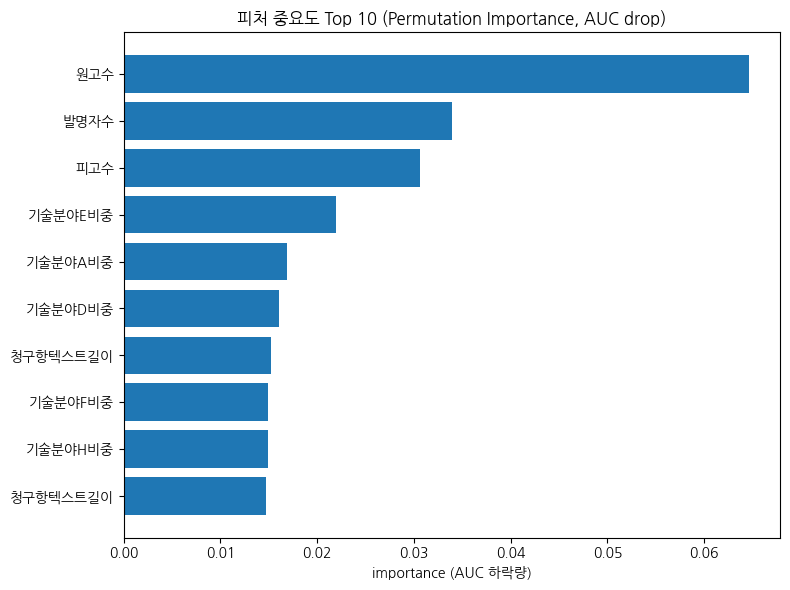

In [10]:
ext = final_models['Extended']
perm = permutation_importance(ext['model'], ext['X_test_sc'], ext['y_test'],
                               n_repeats=30, random_state=RANDOM_STATE, scoring='roc_auc', n_jobs=-1)

importance_df = (
    pd.DataFrame({'feature': ext['feat_cols'], 'importance_mean': perm.importances_mean, 'importance_std': perm.importances_std})
    .sort_values('importance_mean', ascending=False)
    .reset_index(drop=True)
)
print('=== Extended 모델 피처 중요도 (permutation, AUC 기준) — 상위 20개 ===')
print(importance_df.head(20).to_string(index=False))
n_negative_or_zero = (importance_df['importance_mean'] <= 0).sum()
print(f'\n중요도 0 이하(노이즈 가능성): {n_negative_or_zero}/{len(importance_df)}개')
print(importance_df[importance_df['feature'].isin(BASELINE_FEATS)])

_FEATURE_KO = {
    'plaintiff': '원고수', 'defendant': '피고수',
    '출원수': '출원수', '권리자변동이력': '권리자변동이력', '소송특허수': '소송특허수',
    'MCD': '메인분류수', 'SCD': '서브분류수',
    'TD_A': '기술분야A비중', 'TD_B': '기술분야B비중', 'TD_C': '기술분야C비중', 'TD_D': '기술분야D비중',
    'TD_E': '기술분야E비중', 'TD_F': '기술분야F비중', 'TD_G': '기술분야G비중', 'TD_H': '기술분야H비중',
    'ABS': '초록길이', 'CTS': '청구항수', 'CTC': '청구항텍스트길이', 'PTS': '독립항수',
    'PK': '후방인용수', 'SK': '비특허인용수', 'PPS': '해외출원국가수',
    'IE': '발명자수', 'FIE': '해외발명자국가수', 'ET': '등록소요기간',
}
def koreanize_feature(name):
    base = name.replace('_mean', '').replace('_max', '')
    return _FEATURE_KO.get(base, base)

importance_df['feature_ko'] = importance_df['feature'].apply(koreanize_feature)

plt.figure(figsize=(8, 6))
top10 = importance_df.head(10)
y_pos = range(len(top10))
plt.barh(y_pos, top10['importance_mean'][::-1])
plt.yticks(y_pos, top10['feature_ko'][::-1])
plt.title('피처 중요도 Top 10 (Permutation Importance, AUC drop)')
plt.xlabel('importance (AUC 하락량)')
plt.tight_layout()
plt.show()

---
#### 9. LightGBM 비교 
지금까지 MLPClassifier로만 비교했는데, 같은 데이터(`matched`, 1,794건 정확매칭 균형 데이터셋)·같은 baseline/extended 피처 세트로 LightGBM 결과도 같이 확인한다.
트리 기반 모델이라 `StandardScaler` 불필요, 원본 피처 그대로 사용.

In [11]:
import lightgbm as lgb

lgbm_models = {}

print('=== 단일 분할 (test_size=0.2, stratify=y, random_state=42) ===')
for exp_name, feat_cols in [('Baseline', BASELINE_FEATS), ('Extended', EXTENDED_FEATS)]:
    X_train, X_test, y_train, y_test = train_test_split(matched[feat_cols], y, test_size=0.2, random_state=42, stratify=y)

    model = lgb.LGBMClassifier(random_state=42, verbosity=-1)
    model.fit(X_train, y_train)
    pred_y = model.predict(X_test)

    lgbm_models[exp_name] = {'model': model, 'feat_cols': feat_cols, 'X_test': X_test, 'y_test': y_test,
                              'train_acc': model.score(X_train, y_train), 'test_acc': model.score(X_test, y_test)}

    print(f"\n--- {exp_name} ({len(feat_cols)}개 피처) train={len(X_train)} test={len(X_test)} ---")
    print(f"train acc {lgbm_models[exp_name]['train_acc']:.4f}  test acc {lgbm_models[exp_name]['test_acc']:.4f}")
    print(confusion_matrix(y_test, pred_y))
    print(classification_report(y_test, pred_y))

print('\n=== 5-Fold CV ===')
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
for exp_name, feat_cols in [('Baseline', BASELINE_FEATS), ('Extended', EXTENDED_FEATS)]:
    X = matched[feat_cols].values
    model = lgb.LGBMClassifier(random_state=42, verbosity=-1)
    auc = cross_val_score(model, X, y, cv=cv, scoring='roc_auc').mean()
    f1  = cross_val_score(model, X, y, cv=cv, scoring='f1').mean()
    acc = cross_val_score(model, X, y, cv=cv, scoring='accuracy').mean()
    print(f'{exp_name:<10} ({len(feat_cols)}개 피처)  AUC={auc:.4f}  F1={f1:.4f}  Acc={acc:.4f}')

=== 단일 분할 (test_size=0.2, stratify=y, random_state=42) ===

--- Baseline (4개 피처) train=1435 test=359 ---
train acc 0.8843  test acc 0.7827
[[146  34]
 [ 44 135]]
              precision    recall  f1-score   support

           0       0.77      0.81      0.79       180
           1       0.80      0.75      0.78       179

    accuracy                           0.78       359
   macro avg       0.78      0.78      0.78       359
weighted avg       0.78      0.78      0.78       359


--- Extended (45개 피처) train=1435 test=359 ---
train acc 1.0000  test acc 0.8524
[[150  30]
 [ 23 156]]
              precision    recall  f1-score   support

           0       0.87      0.83      0.85       180
           1       0.84      0.87      0.85       179

    accuracy                           0.85       359
   macro avg       0.85      0.85      0.85       359
weighted avg       0.85      0.85      0.85       359


=== 5-Fold CV ===
Baseline   (4개 피처)  AUC=0.8422  F1=0.7698  Acc=0.7737
Extende

#### 9-1. LightGBM 피처 중요도 (네이티브 `feature_importances_`, Top 10, 한글 라벨)

=== Extended 모델 피처 중요도 (LightGBM 네이티브) — 상위 20개 ===
  feature  importance
plaintiff         248
  ET_mean         212
      출원수         189
 CTC_mean         163
  CTC_max         152
 ABS_mean         150
  PK_mean         146
 CTS_mean         144
   ET_max         140
  IE_mean         130
  ABS_max         124
  SK_mean         121
  권리자변동이력         110
   PK_max         103
defendant         103
TD_G_mean          98
 PTS_mean          96
  CTS_max          91
TD_H_mean          80
    소송특허수          75
      feature  importance
0   plaintiff         248
2         출원수         189
12    권리자변동이력         110
14  defendant         103


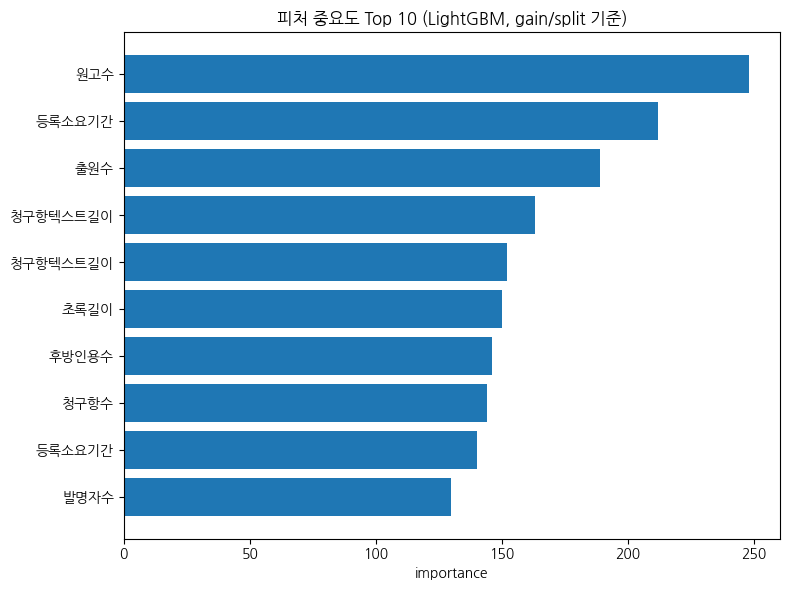

In [12]:
lgbm_ext = lgbm_models['Extended']
lgbm_importance_df = (
    pd.DataFrame({'feature': lgbm_ext['feat_cols'], 'importance': lgbm_ext['model'].feature_importances_})
    .sort_values('importance', ascending=False)
    .reset_index(drop=True)
)
print('=== Extended 모델 피처 중요도 (LightGBM 네이티브) — 상위 20개 ===')
print(lgbm_importance_df.head(20).to_string(index=False))
print(lgbm_importance_df[lgbm_importance_df['feature'].isin(BASELINE_FEATS)])

_FEATURE_KO = {
    'plaintiff': '원고수', 'defendant': '피고수',
    '출원수': '출원수', '권리자변동이력': '권리자변동이력', '소송특허수': '소송특허수',
    'MCD': '메인분류수', 'SCD': '서브분류수',
    'TD_A': '기술분야A비중', 'TD_B': '기술분야B비중', 'TD_C': '기술분야C비중', 'TD_D': '기술분야D비중',
    'TD_E': '기술분야E비중', 'TD_F': '기술분야F비중', 'TD_G': '기술분야G비중', 'TD_H': '기술분야H비중',
    'ABS': '초록길이', 'CTS': '청구항수', 'CTC': '청구항텍스트길이', 'PTS': '독립항수',
    'PK': '후방인용수', 'SK': '비특허인용수', 'PPS': '해외출원국가수',
    'IE': '발명자수', 'FIE': '해외발명자국가수', 'ET': '등록소요기간',
}
def koreanize_feature(name):
    base = name.replace('_mean', '').replace('_max', '')
    return _FEATURE_KO.get(base, base)

lgbm_importance_df['feature_ko'] = lgbm_importance_df['feature'].apply(koreanize_feature)

plt.figure(figsize=(8, 6))
top10 = lgbm_importance_df.head(10)
y_pos = range(len(top10))
plt.barh(y_pos, top10['importance'][::-1])
plt.yticks(y_pos, top10['feature_ko'][::-1])
plt.title('피처 중요도 Top 10 (LightGBM, gain/split 기준)')
plt.xlabel('importance')
plt.tight_layout()
plt.show()